# Lab 4: Fault Locking, Creep, and the Earthquake Cycle

> **Colab note:** This notebook is designed to run on **Google Colab**. [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/amtseismo/EPS166/blob/main/notebooks/04_seismic_cycle.ipynb)

## Introduction

In lecture we followed deformation through the full earthquake cycle — from slow interseismic strain accumulation, through coseismic slip, to postseismic relaxation. In this lab you will work with real geodetic data from two California fault systems to see each phase directly.

In the first half you will fit the Savage–Burford interseismic model to GNSS velocity profiles across the San Andreas, compare a locked segment to a creeping one, and convert the inferred slip deficit into an earthquake moment budget. In the second half you will work with coseismic GNSS offsets from the 2019 Ridgecrest M7.1 earthquake and postseismic time series to identify the mechanisms of postseismic relaxation.

## Learning objectives

- Rotate GNSS velocities into fault-parallel and fault-perpendicular components
- Fit the Savage–Burford arctangent model and interpret slip rate and locking depth
- Distinguish broad elastic strain accumulation from localized fault creep
- Convert a slip deficit into an earthquake moment budget without treating it as a prediction
- Map and model coseismic GNSS offsets and fit the 1D coseismic dislocation model
- Identify afterslip in a postseismic GNSS time series and fit a logarithmic decay model

## Outline

**Part I: Interseismic**
1. [Setup](#1-setup)
2. [Load and standardize the velocity table](#2-load-and-standardize-the-velocity-table)
3. [Define San Andreas coordinates](#3-define-san-andreas-coordinates)
4. [Guided example: the Carrizo segment](#4-guided-example-the-carrizo-segment)
5. [Fit the arctangent locking model](#5-fit-the-arctangent-locking-model)
6. [Creep: locked versus creeping behavior](#6-creep-locked-versus-creeping-behavior)
7. [San Juan Bautista: a creeping segment](#7-san-juan-bautista-a-creeping-segment)
8. [Slip deficit and moment budget](#8-slip-deficit-and-moment-budget)

**Part II: Coseismic**

9. [Ridgecrest M7.1 coseismic offsets](#9-ridgecrest-m71-coseismic-offsets)
10. [Fit the 1D coseismic dislocation model](#10-fit-the-1d-coseismic-dislocation-model)

**Part III: Postseismic**

11. [Ridgecrest postseismic time series](#11-ridgecrest-postseismic-time-series)
12. [Fit a logarithmic afterslip model](#12-fit-a-logarithmic-afterslip-model)

13. [Synthesis](#13-synthesis)

Archived velocity data: [Kreemer et al. (2022)](https://doi.org/10.7910/DVN/BICMWB)  
Coseismic offsets: [Nevada Geodetic Laboratory, UNR](https://geodesy.unr.edu/news_items/20190707/ci38457511_forweb.txt)  
Postseismic time series: [Nevada Geodetic Laboratory tenv3 archive](http://geodesy.unr.edu/gps_timeseries/tenv3/IGS14/)


## 1. Setup

Run this cell to import packages and set the dataset URL. Data are loaded directly from the course GitHub repository — no local files are needed.


In [1]:
import io
import re
import zipfile
from pathlib import Path
import urllib.request
from urllib.request import urlopen

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

plt.rcParams.update({
    "figure.dpi": 120,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

DATA_URL = "https://github.com/amtseismo/EPS166/raw/main/datasets/Kreemer_GPS_table.txt"

## 2. Load and standardize the velocity table

The archive may use names such as `Ve`, `Evel`, or `east_velocity` for the same quantity. The next cells parse the table and map its columns onto a common set of names.


In [2]:
print(f"Downloading velocity table from:\n  {DATA_URL}")
try:
    velocity_raw = pd.read_csv(DATA_URL, sep=r"\s+")
except Exception as error:
    raise RuntimeError(
        f"Download failed: {error}\n"
        "Check your internet connection and that the URL is accessible."
    ) from error

print(f"Rows: {len(velocity_raw):,};  columns: {velocity_raw.shape[1]}")
print("Column names:", list(velocity_raw.columns))
display(velocity_raw.head())


  https://github.com/amtseismo/EPS166/raw/main/datasets/Kreemer_GPS_table.txt
Rows: 3,048;  columns: 10
Column names: ['lon', 'lat', 've', 'vn', 'sdve', 'sdvn', 've_p', 'vn_p', 'stat', 'source']


,lon,lat,ve,vn,sdve,sdvn,ve_p,vn_p,stat,source
0,-112.183,33.431,-3.96,1.96,0.18,0.11,2.15,-0.35,59WE,#
1,-114.759,37.595,-3.62,3.11,0.25,0.18,1.03,-1.21,7OAK,#
2,-117.093,34.116,-16.81,15.71,0.18,0.18,1.01,2.20,7ODM,#
3,-113.573,50.016,2.49,2.19,0.36,0.33,-1.77,-1.38,ABCH,#
4,-112.835,49.706,3.14,1.77,0.31,0.28,-1.76,-1.26,ABLT,#


In [3]:
COLUMN_MAP = {
    "station": None,
    "lon": None,
    "lat": None,
    "ve": None,
    "vn": None,
    "se": None,   # optional — falls back to a default if not found
    "sn": None,   # optional — falls back to a default if not found
}

ALIASES = {
    "station": ["station", "site", "sta", "name", "code", "id"],
    "lon": ["longitude", "lon", "long"],
    "lat": ["latitude", "lat"],
    "ve": ["ve", "v_e", "eastvelocity", "east_vel", "evel", "vel_e", "east"],
    "vn": ["vn", "v_n", "northvelocity", "north_vel", "nvel", "vel_n", "north"],
    "se": ["se", "sdve", "sde", "sve", "sig_e", "sigma_e", "east_sigma", "east_unc", "e_unc", "s_e", "err_e"],
    "sn": ["sn", "sdvn", "sdn", "svn", "sig_n", "sigma_n", "north_sigma", "north_unc", "n_unc", "s_n", "err_n"],
}

REQUIRED = ["station", "lon", "lat", "ve", "vn"]
OPTIONAL = ["se", "sn"]


def canonical(text):
    return re.sub(r"[^a-z0-9]", "", str(text).lower())


def infer_column(columns, aliases):
    normalized = {canonical(c): c for c in columns}
    for alias in aliases:
        if canonical(alias) in normalized:
            return normalized[canonical(alias)]
    for alias in aliases:
        matches = [original for key, original in normalized.items()
                   if key.startswith(canonical(alias))]
        if len(matches) == 1:
            return matches[0]
    return None


for key in COLUMN_MAP:
    if COLUMN_MAP[key] is None:
        COLUMN_MAP[key] = infer_column(velocity_raw.columns, ALIASES[key])

print("Detected column mapping:")
for key, value in COLUMN_MAP.items():
    print(f"  {key:>7s} <- {value}")

# Only required columns must be found
missing_required = [k for k in REQUIRED if COLUMN_MAP[k] is None]
if missing_required:
    raise KeyError(
        f"Could not identify required columns {missing_required}.\n"
        f"Available columns: {list(velocity_raw.columns)}\n"
        "Edit COLUMN_MAP manually above."
    )

# Build the velocity table from required columns
velocity = velocity_raw[[COLUMN_MAP[k] for k in REQUIRED]].copy()
velocity.columns = REQUIRED

# Add optional uncertainty columns; use a default of 1.0 mm/yr if not found
DEFAULT_SIGMA = 1.0   # mm/yr
for key in OPTIONAL:
    if COLUMN_MAP[key] is not None:
        velocity[key] = pd.to_numeric(
            velocity_raw[COLUMN_MAP[key]].values, errors="coerce"
        )
        n_missing = velocity[key].isna().sum()
        if n_missing:
            print(f"  {key}: {n_missing} NaN values replaced with default {DEFAULT_SIGMA} mm/yr")
        velocity[key] = velocity[key].fillna(DEFAULT_SIGMA)
    else:
        print(f"  {key}: column not found — using default uncertainty of {DEFAULT_SIGMA} mm/yr")
        velocity[key] = DEFAULT_SIGMA

# Convert velocity/position columns to numeric and drop rows missing essentials
for col in ["lon", "lat", "ve", "vn"]:
    velocity[col] = pd.to_numeric(velocity[col], errors="coerce")
velocity = velocity.dropna(subset=["lon", "lat", "ve", "vn"]).copy()
velocity["station"] = velocity.station.astype(str)

VELOCITY_SCALE_TO_MM_PER_YR = 1.0  # Change if the archive uses m/yr.
for col in ["ve", "vn", "se", "sn"]:
    velocity[col] *= VELOCITY_SCALE_TO_MM_PER_YR

display(velocity.head())
print(f"Usable velocities: {len(velocity):,}")
print(velocity[["ve", "vn"]].describe())


Detected column mapping:
  station <- stat
      lon <- lon
      lat <- lat
       ve <- ve
       vn <- vn
       se <- sdve
       sn <- sdvn
  se: 13 NaN values replaced with default 1.0 mm/yr
  sn: 13 NaN values replaced with default 1.0 mm/yr


,station,lon,lat,ve,vn,se,sn
0,59WE,-112.183,33.431,-3.96,1.96,0.18,0.11
1,7OAK,-114.759,37.595,-3.62,3.11,0.25,0.18
2,7ODM,-117.093,34.116,-16.81,15.71,0.18,0.18
3,ABCH,-113.573,50.016,2.49,2.19,0.36,0.33
4,ABLT,-112.835,49.706,3.14,1.77,0.31,0.28


Usable velocities: 3,035
                ve           vn
count  3035.000000  3035.000000
mean     -7.878079    12.157157
std      10.662725     9.990935
min     -37.540000    -0.250000
25%     -16.180000     4.070000
50%      -4.990000     8.770000
75%       0.000000    19.315000
max      13.020000    38.670000


### Data check

The cell below prints the velocity range and a quick sanity check. Use it to confirm:

1. `ve` and `vn` are the velocities used in the analysis, not postseismic correction terms.
2. The velocities are **North America-fixed**: California stations should have `ve` roughly −10 to −40 mm/yr (westward relative to stable North America) and small `vn`.
3. The values are in **millimeters per year**: typical magnitudes should be single digits to tens of mm/yr, not fractions (m/yr) or hundreds (km/yr).

Why would fitting uncorrected postseismic velocities bias an interseismic locking model?

Answer: Any uncorrected velocities can affect a model with higher inaccuracies, but postseismic velocities are directly related to the interseismic period. If your postseismic velocities are incorrect, then you understanding of the interseismic period will be incorrect.

In [4]:
# Sanity check on the loaded velocity table.
# California stations should have ve ~ -10 to -40 mm/yr (westward relative to North America)
# and small vn. Values in this range confirm correct units (mm/yr) and reference frame (NA-fixed).

california = velocity[
    velocity.lon.between(-125, -114) & velocity.lat.between(32, 42)
].copy()
print(f"California stations: {len(california)}")
print(f"\nEast velocity (mm/yr):  "
      f"mean={california.ve.mean():.1f},  std={california.ve.std():.1f},  "
      f"range=[{california.ve.min():.1f}, {california.ve.max():.1f}]")
print(f"North velocity (mm/yr): "
      f"mean={california.vn.mean():.1f},  std={california.vn.std():.1f},  "
      f"range=[{california.vn.min():.1f}, {california.vn.max():.1f}]")
print()
if abs(california.ve.mean()) < 1.0:
    print("\u26a0  ve looks too small \u2014 may be in m/yr. Set VELOCITY_SCALE_TO_MM_PER_YR = 1000 in Cell 5 and rerun.")
elif abs(california.ve.mean()) > 200:
    print("\u26a0  ve looks too large \u2014 check units.")
else:
    print("\u2713  Units look correct (mm/yr).")

if california.ve.mean() > 0:
    print("\u26a0  Mean ve is positive \u2014 reference frame may not be North America-fixed.")
else:
    print("\u2713  Reference frame looks correct (NA-fixed: CA moves west, ve < 0).")


California stations: 1835

East velocity (mm/yr):  mean=-13.9,  std=8.6,  range=[-34.1, 1.9]
North velocity (mm/yr): mean=16.5,  std=10.0,  range=[-0.2, 38.7]

✓  Units look correct (mm/yr).
✓  Reference frame looks correct (NA-fixed: CA moves west, ve < 0).


## 3. Define San Andreas coordinates

We approximate a short fault segment as a straight line with strike $\alpha$, measured clockwise from north. The origin is a point on the fault.

We define positive fault-perpendicular distance toward the **left side** of the fault when looking along strike. For the northwest-striking San Andreas, this is approximately toward the Pacific side.


In [5]:
EARTH_RADIUS_KM = 6371.0


def geographic_offsets_km(lon, lat, origin_lon, origin_lat):
    """Small-distance east and north offsets from an origin."""
    east = EARTH_RADIUS_KM * np.cos(np.deg2rad(origin_lat)) * np.deg2rad(np.asarray(lon) - origin_lon)
    north = EARTH_RADIUS_KM * np.deg2rad(np.asarray(lat) - origin_lat)
    return east, north


def rotate_to_fault_coordinates(table, origin_lon, origin_lat, strike_deg):
    """Add fault-parallel/perpendicular positions and velocities."""
    result = table.copy()
    east, north = geographic_offsets_km(result.lon, result.lat, origin_lon, origin_lat)
    strike = np.deg2rad(strike_deg)

    # Parallel is positive along strike. Perpendicular is positive to the left.
    result["x_parallel_km"] = east*np.sin(strike) + north*np.cos(strike)
    result["x_perp_km"] = -east*np.cos(strike) + north*np.sin(strike)
    result["v_parallel"] = result.ve*np.sin(strike) + result.vn*np.cos(strike)
    result["v_perp"] = -result.ve*np.cos(strike) + result.vn*np.sin(strike)
    result["s_parallel"] = np.sqrt(
        (result.se*np.sin(strike))**2 + (result.sn*np.cos(strike))**2
    )
    positive_sigma = result.loc[result.s_parallel > 0, "s_parallel"]
    if len(positive_sigma):
        result.loc[result.s_parallel <= 0, "s_parallel"] = positive_sigma.median()
    return result


def add_state_outlines(ax, state_codes=("CA", "NV")):
    try:
        from bokeh.sampledata.us_states import data as states
        for code in state_codes:
            ax.plot(states[code]["lons"], states[code]["lats"], color="0.4", lw=0.8, zorder=0)
    except Exception:
        pass


### Predict the transformation

For a station moving northwest approximately parallel to the San Andreas:

1. Will most of its motion appear in $v_{\parallel}$ or $v_{\perp}$?
2. Does rotating the axes change the station's actual velocity magnitude?
3. Why is a narrow along-strike sampling window important for a one-dimensional profile?

Answers:
1. For a station moving parallel to the fault, its motion will appear parallel.
2. rotating your axes should not change the stations actualy velocity as long as your reference to the station changes accordingly with your axes changes
3. You want to capture only one clear event in the window, as opposed to lots of data within a greater sampling window.


## 4. Guided example: the Mojave segment

The values below define a straight section of the San Andreas fault through the
central Mojave Desert. The Mojave segment is one of the cleanest profiles on the
SAF for this exercise: the desert avoids the non-tectonic groundwater-extraction
signals that contaminate the Carrizo Plain region northeast of the fault, the
fault trace is straight over ~150 km, and the SCIGN network provides dense
coverage on both sides.

The `origin` point sits on the fault trace near Victorville. The strike (308°)
approximates the local trend. Adjust `along_halfwidth_km` or
`cross_halfwidth_km` if you want to widen or narrow the profile window.


In [6]:
MOJAVE = {
    "origin_lon": -117.75,
    "origin_lat": 34.50,
    "strike_deg": 308.0,
    "along_halfwidth_km": 60.0,
    "cross_halfwidth_km": 250.0,
}

mojave_all = rotate_to_fault_coordinates(
    velocity,
    MOJAVE["origin_lon"], MOJAVE["origin_lat"], MOJAVE["strike_deg"]
)
mojave = mojave_all[
    mojave_all.x_parallel_km.abs().le(MOJAVE["along_halfwidth_km"])
    & mojave_all.x_perp_km.abs().le(MOJAVE["cross_halfwidth_km"])
].copy()

print(f"Selected {len(mojave)} stations")
display(mojave[["station", "lon", "lat", "x_perp_km", "x_parallel_km", "v_parallel"]].head())


Selected 229 stations


,station,lon,lat,x_perp_km,x_parallel_km,v_parallel
17,AIAH,-117.862,33.849,63.361301,-36.478668,34.112212
31,AOA1,-118.830,34.157,90.986478,54.507980,38.246657
50,AVRY,-117.154,34.468,-30.821429,-45.229166,19.240908
100,AZU1,-117.896,34.126,41.008011,-15.060466,31.994345
109,BAR1,-119.030,33.480,161.590789,22.604069,43.270347


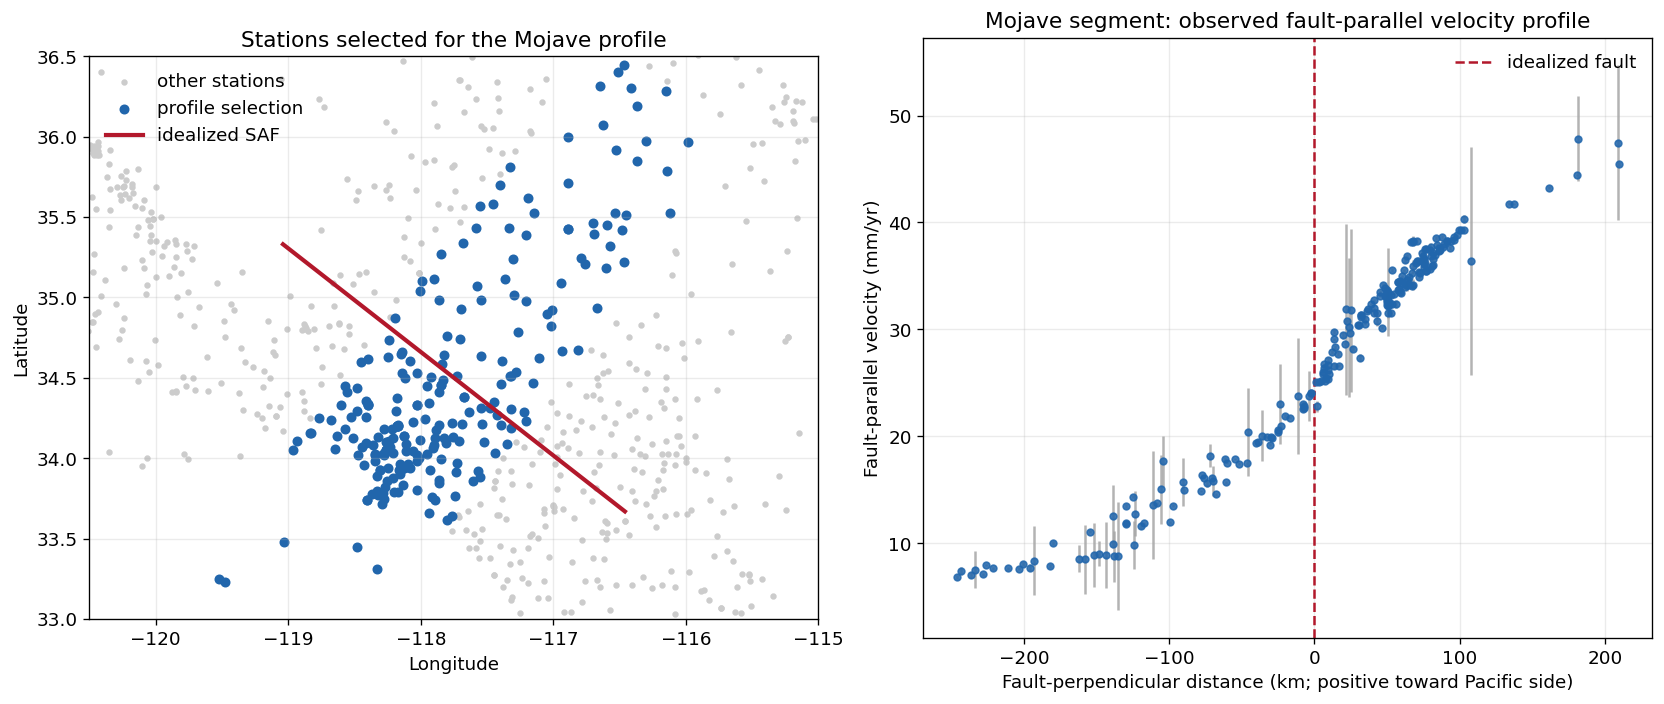

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

ax = axes[0]
add_state_outlines(ax)
ax.scatter(mojave_all.lon, mojave_all.lat, s=8, color="0.8", label="other stations")
ax.scatter(mojave.lon, mojave.lat, s=25, color="#2166ac", label="profile selection")

# Plot the idealized straight fault segment through the origin.
strike = np.deg2rad(MOJAVE["strike_deg"])
lengths = np.array([-150, 150])
fault_e = lengths*np.sin(strike)
fault_n = lengths*np.cos(strike)
fault_lon = MOJAVE["origin_lon"] + np.rad2deg(fault_e/(EARTH_RADIUS_KM*np.cos(np.deg2rad(MOJAVE["origin_lat"]))))
fault_lat = MOJAVE["origin_lat"] + np.rad2deg(fault_n/EARTH_RADIUS_KM)
ax.plot(fault_lon, fault_lat, color="#b2182b", lw=2.5, label="idealized SAF")
ax.set(xlim=(-120.5, -115.0), ylim=(33.0, 36.5), xlabel="Longitude", ylabel="Latitude",
       title="Stations selected for the Mojave profile")
ax.set_aspect(1/np.cos(np.deg2rad(34.5)))
ax.legend(frameon=False)

ax = axes[1]
ax.errorbar(mojave.x_perp_km, mojave.v_parallel, yerr=mojave.s_parallel,
            fmt="o", ms=4, color="#2166ac", ecolor="0.65", alpha=0.85)
ax.axvline(0, color="#b2182b", ls="--", lw=1.5, label="idealized fault")
ax.set(xlabel="Fault-perpendicular distance (km; positive toward Pacific side)",
       ylabel="Fault-parallel velocity (mm/yr)", title="Mojave segment: observed fault-parallel velocity profile")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()


### Inspect before fitting

1. Does the velocity profile resemble an arctangent?
2. What approximate far-field velocity difference do you see?
3. Are the two sides sampled equally well?
4. Identify any stations that appear inconsistent with the overall trend. Should they automatically be removed?

Answers:
1. Yes the velocity profile resemble the curve of an arctan, with the downward curve rising to the upward
2. There are big gaps in velocity from past 100 km, ranging from 40-50mm/year.
3. both sides have lots of data, but there is large clustering on the right side of the fault, making me think there is more data sampling on the right then the left.
4. There are very few points that I believe are inconsistent, as they are a bit higher up than other points within the trend, but I do not think they should be removed right away, as we can see more results with these stations, and then decide if they should be removed.  

## 5. Fit the arctangent locking model

We fit

$$
v_{\parallel}(x) = v_0 + \frac{V}{\pi}\tan^{-1}\!\left(\frac{x}{D}\right).
$$

The model parameters are the relative slip rate $V$, locking depth $D$, and
reference velocity $v_0$. The offset $v_0$ absorbs the arbitrary constant of
the GNSS reference frame and is not related to the coupling fraction $C$
introduced in Section 6.


In [8]:
def arctan_velocity(x_km, slip_rate_mm_yr, locking_depth_km, offset_mm_yr):
    return offset_mm_yr + slip_rate_mm_yr/np.pi * np.arctan(x_km/locking_depth_km)


initial_guess = [35.0, 15.0, np.median(mojave.v_parallel)]
bounds = ([0.0, 1.0, -100.0], [100.0, 80.0, 100.0])

parameters, covariance = curve_fit(
    arctan_velocity,
    mojave.x_perp_km,
    mojave.v_parallel,
    p0=initial_guess,
    sigma=mojave.s_parallel,
    absolute_sigma=True,
    bounds=bounds,
)
parameter_sigma = np.sqrt(np.diag(covariance))
V_fit, D_fit, c_fit = parameters

results = pd.DataFrame({
    "estimate": parameters,
    "formal_sigma": parameter_sigma,
    "units": ["mm/yr", "km", "mm/yr"],
}, index=["slip rate V", "locking depth D", "reference velocity v₀"])
display(results)


,estimate,formal_sigma,units
slip rate V,44.962744,0.170843,mm/yr
locking depth D,80.000000,0.543920,km
reference velocity v₀,25.527080,0.013783,mm/yr


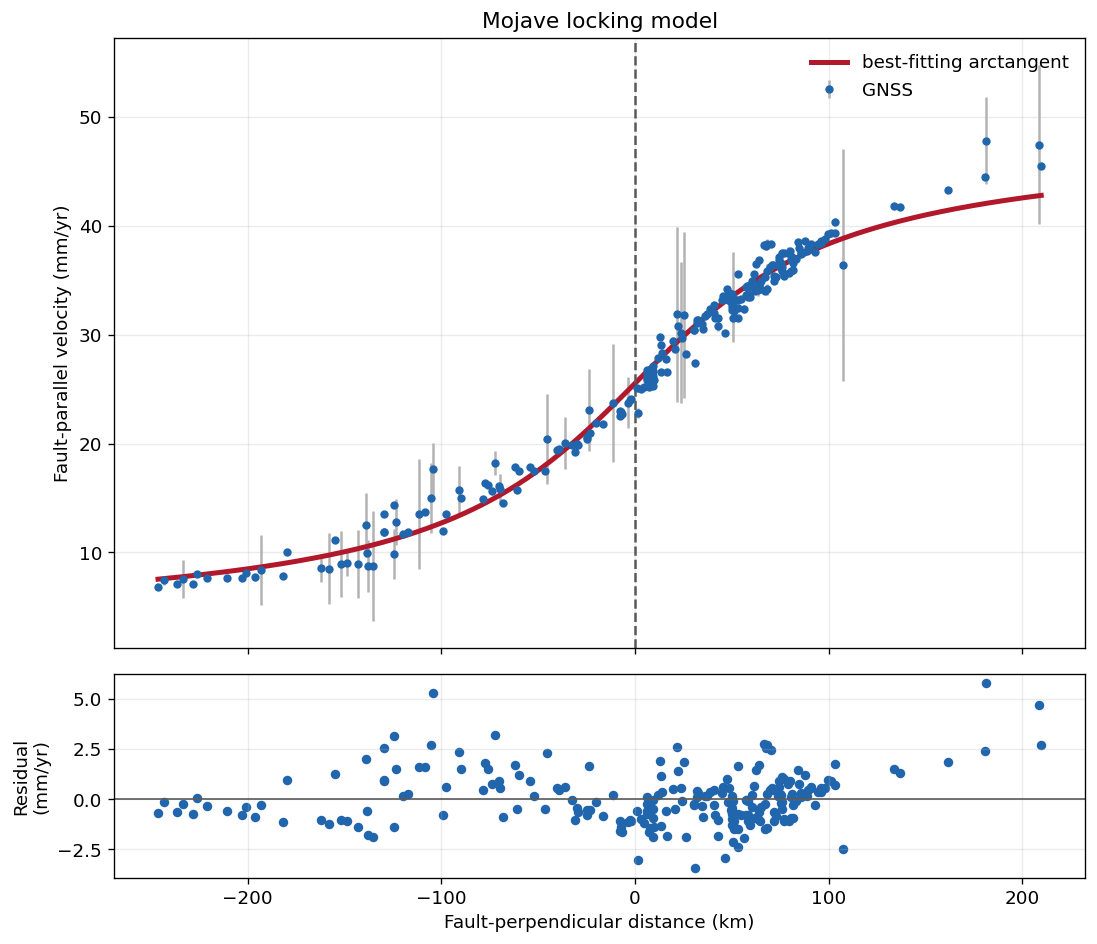

RMS residual: 1.33 mm/yr


In [9]:
x_model = np.linspace(mojave.x_perp_km.min(), mojave.x_perp_km.max(), 600)
v_model = arctan_velocity(x_model, *parameters)
v_predicted = arctan_velocity(mojave.x_perp_km, *parameters)
residual = mojave.v_parallel - v_predicted

fig, axes = plt.subplots(2, 1, figsize=(9, 8), sharex=True,
                         gridspec_kw={"height_ratios": [3, 1]})
axes[0].errorbar(mojave.x_perp_km, mojave.v_parallel, yerr=mojave.s_parallel,
                 fmt="o", ms=4, color="#2166ac", ecolor="0.7", label="GNSS")
axes[0].plot(x_model, v_model, color="#b2182b", lw=3, label="best-fitting arctangent")
axes[0].axvline(0, color="0.35", ls="--")
axes[0].set(ylabel="Fault-parallel velocity (mm/yr)", title="Mojave locking model")
axes[0].legend(frameon=False)

axes[1].axhline(0, color="0.35", lw=1)
axes[1].scatter(mojave.x_perp_km, residual, s=22, color="#2166ac")
axes[1].set(xlabel="Fault-perpendicular distance (km)", ylabel="Residual\n(mm/yr)")
plt.tight_layout()
plt.show()

print(f"RMS residual: {np.sqrt(np.mean(residual**2)):.2f} mm/yr")


### Interpret the model

1. Report the estimated slip rate and locking depth.
2. Which feature of the curve constrains slip rate? Which constrains locking depth?
3. Do residuals vary randomly, or are nearby stations systematically above or below the model?
4. Name two physical assumptions of the model that are violated by the real San Andreas system.

Answers:
1.

## 6. Creep: locked versus creeping behavior

The Savage–Burford model assumes a fully locked fault. Real faults are partially coupled: some fraction $C$ of the long-term plate motion accumulates as elastic strain, while the rest is released continuously by aseismic creep at the surface.

We model partial coupling as the sum of two contributions:

- a **broad locked-fault** term with coupling fraction $C$, producing the arctangent profile
- a **narrow creeping** term with fraction $1-C$, producing a sharp velocity step at the surface

The full model is

$$
v_{\parallel}(x) = v_0 + C\,\frac{V}{\pi}\arctan\!\left(\frac{x}{D}\right)
          + (1-C)\,\frac{V}{2}\tanh\!\left(\frac{x}{w}\right)
$$

where $C$ is the coupling fraction ($C=1$: fully locked, $C=0$: fully creeping),
$w$ is the surface creep width, and $v_0$ is the same reference offset as before.

The narrow creeping term uses $\tanh(x/w)$ rather than an ideal step function to avoid a mathematical discontinuity. For a small creep width $w$ (here 1 km), this closely approximates the sudden velocity offset you would see if a fault creeps all the way to the surface.

When $C=1$ the fault is fully locked; when $C=0$ the fault creeps freely at the full plate rate.

> **These three curves are synthetic** — they use the Carrizo slip rate and locking depth from Part I, varied only in coupling fraction. The goal is to build intuition about what creep does to a velocity profile before you look at real data.


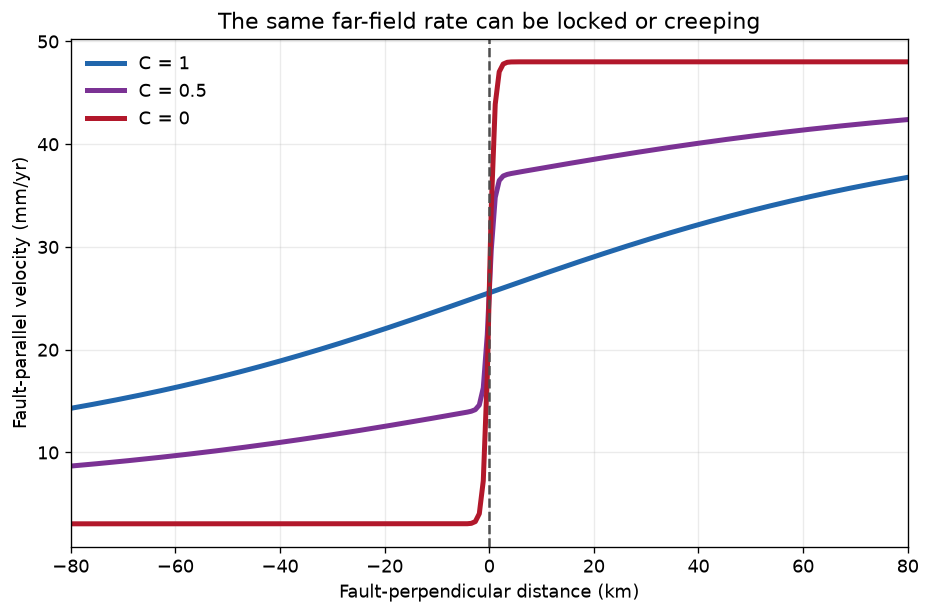

In [ ]:
def coupled_velocity(x_km, slip_rate, locking_depth, offset, coupling, creep_width_km=1.0):
    locked = coupling * slip_rate/np.pi * np.arctan(x_km/locking_depth)
    creeping = (1-coupling) * slip_rate/2 * np.tanh(x_km/creep_width_km)
    return offset + locked + creeping


fig, ax = plt.subplots(figsize=(9, 5.5))
for coupling, color in zip([1.0, 0.5, 0.0], ["#2166ac", "#7b3294", "#b2182b"]):
    ax.plot(x_model, coupled_velocity(x_model, V_fit, D_fit, c_fit, coupling),
            lw=3, color=color, label=f"C = {coupling:g}")
ax.set(xlim=(-80, 80), xlabel="Fault-perpendicular distance (km)",
       ylabel="Fault-parallel velocity (mm/yr)",
       title="The same far-field rate can be locked or creeping")
ax.axvline(0, color="0.3", ls="--")
ax.legend(frameon=False)
plt.show()


### Creep interpretation

1. Which curve stores the greatest elastic strain near the fault?
2. Which curve has the largest velocity change immediately at the fault?
3. Do all curves accommodate the same long-term far-field motion?
4. Where would you place GNSS stations to distinguish partial coupling from full locking?
5. Would a station spacing of 50 km resolve a 1-km-wide creeping zone?

> **Before looking at San Juan Bautista:** The central San Andreas near San Juan Bautista creeps at approximately 22–25 mm/yr aseismically — nearly the full plate rate. Based on the synthetic curves above, predict what the San Juan Bautista velocity profile will look like compared to the Mojave segment. Which coupling end-member ($C \approx 0$, $C \approx 0.5$, or $C \approx 1$) do you expect, and why?


## 7. San Juan Bautista: an unambiguously creeping segment

The central San Andreas fault between San Juan Bautista and Hollister creeps
aseismically at approximately 22–25 mm/yr — nearly the full plate rate — with
no significant locked patches at the surface. This makes it the cleanest place
on the SAF to observe the sharp near-fault velocity step that distinguishes a
creeping fault from a locked one.

Parkfield lies at the *transition* between the creeping central segment and the
locked southern segment, so its profile is a mix of both behaviours and harder
to interpret cleanly. The San Juan Bautista region has the sharp near-fault
velocity change without that ambiguity.

Apply the same coordinate rotation and profile extraction here, then fit the
`coupled_velocity` model with coupling fraction $C$ as a free parameter.

> **Before fitting:** Based on the synthetic curves in Section 6, predict what
> this profile will look like. Which coupling end-member ($C \approx 0$,
> $C \approx 0.5$, or $C \approx 1$) do you expect, and why?


Selected 32 stations


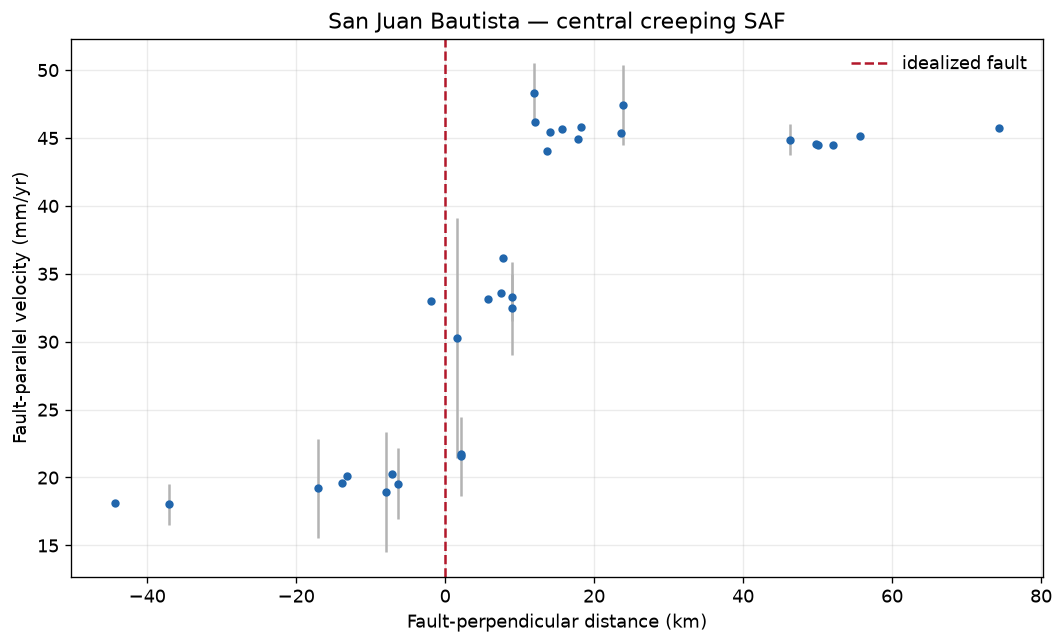

In [ ]:
# San Juan Bautista — central creeping SAF
# This segment creeps at ~22–25 mm/yr, nearly the full plate rate.
# The narrow along-halfwidth keeps us on the straight creeping section
# and away from the transition to the locked Mojave segment to the south.
SJB = {
    "origin_lon": -121.30,
    "origin_lat": 36.80,
    "strike_deg": 315.0,
    "along_halfwidth_km": 25.0,
    "cross_halfwidth_km": 80.0,
}

sjb_all = rotate_to_fault_coordinates(
    velocity,
    SJB["origin_lon"], SJB["origin_lat"], SJB["strike_deg"]
)
sjb = sjb_all[
    sjb_all.x_parallel_km.abs().le(SJB["along_halfwidth_km"])
    & sjb_all.x_perp_km.abs().le(SJB["cross_halfwidth_km"])
].copy()

print(f"Selected {len(sjb)} stations")

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.errorbar(sjb.x_perp_km, sjb.v_parallel, yerr=sjb.s_parallel,
            fmt="o", ms=4, color="#2166ac", ecolor="0.7")
ax.axvline(0, color="#b2182b", ls="--", label="idealized fault")
ax.set(xlabel="Fault-perpendicular distance (km)", ylabel="Fault-parallel velocity (mm/yr)",
       title="San Juan Bautista — central creeping SAF")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()


> **Inspect the profile before fitting:**
> 1. Does the San Juan Bautista profile show a sharper near-fault velocity change compared to the Mojave segment?
> 2. Would changing only locking depth in the Savage–Burford model reproduce the San Juan Bautista profile shape? Why or why not?
> 3. What direct field observations would confirm surface creep on the fault?
> 4. Why is coupling likely to vary along strike rather than having one value for the entire San Andreas?


Parkfield coupled model fit:
  Slip rate        V = 34.3 ± 0.2 mm/yr
  Locking depth    D = 8.4 ± 0.2 km
  Coupling fraction C = 1.00 ± 0.01  (1 = locked, 0 = creeping)


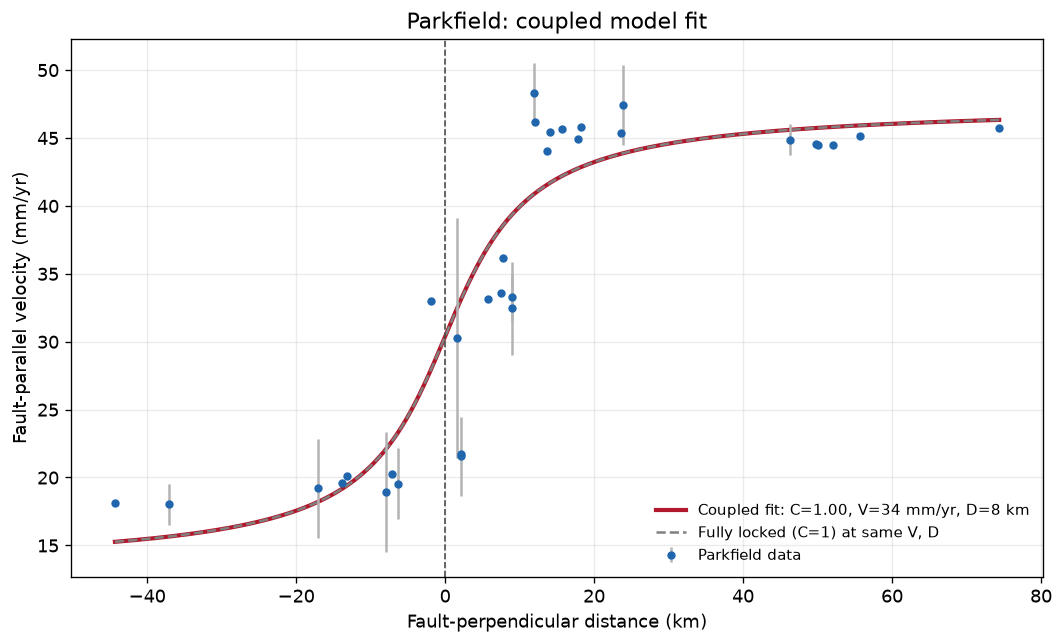

In [ ]:
# Fit the coupled model to San Juan Bautista with coupling fraction C as a free parameter.
# Uses the coupled_velocity function defined in Section 6.

def coupled_velocity_free(x_km, slip_rate, locking_depth, offset, coupling):
    """Wrapper exposing all four parameters for curve_fit."""
    return coupled_velocity(x_km, slip_rate, locking_depth, offset,
                            coupling, creep_width_km=1.0)

# Initial guess: Carrizo slip rate, moderate locking depth, low coupling
p0_pk     = [V_fit, D_fit, np.median(sjb.v_parallel), 0.2]
bounds_pk = ([0.0,  1.0, -100.0, 0.0],
             [80.0, 80.0,  100.0, 1.0])

try:
    popt_pk, pcov_pk = curve_fit(
        coupled_velocity_free,
        sjb.x_perp_km,
        sjb.v_parallel,
        p0=p0_pk, bounds=bounds_pk,
        sigma=sjb.s_parallel,
        absolute_sigma=True,
        maxfev=5000,
    )
    perr_pk = np.sqrt(np.diag(pcov_pk))
    V_pk, D_pk, c_pk, C_pk = popt_pk
    print("San Juan Bautista coupled model fit:")
    print(f"  Slip rate        V = {V_pk:.1f} \u00b1 {perr_pk[0]:.1f} mm/yr")
    print(f"  Locking depth    D = {D_pk:.1f} \u00b1 {perr_pk[1]:.1f} km")
    print(f"  Coupling fraction C = {C_pk:.2f} \u00b1 {perr_pk[3]:.2f}  (1 = locked, 0 = creeping)")
except Exception as e:
    print(f"Fit failed: {e}")
    V_pk, D_pk, c_pk, C_pk = V_fit, D_fit, np.median(sjb.v_parallel), 0.2

# Plot data with coupled fit and the equivalent fully-locked curve
x_pk_model  = np.linspace(sjb.x_perp_km.min(), sjb.x_perp_km.max(), 600)
v_pk_fit    = coupled_velocity_free(x_pk_model, V_pk, D_pk, c_pk, C_pk)
v_pk_locked = arctan_velocity(x_pk_model, V_pk, D_pk, c_pk)   # C=1

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.errorbar(sjb.x_perp_km, sjb.v_parallel, yerr=sjb.s_parallel,
            fmt="o", ms=4, color="#2166ac", ecolor="0.7", label="SJB data", zorder=3)
ax.plot(x_pk_model, v_pk_fit, color="#b2182b", lw=2.5,
        label=f"Coupled fit: C={C_pk:.2f}, V={V_pk:.0f} mm/yr, D={D_pk:.0f} km")
ax.plot(x_pk_model, v_pk_locked, color="0.5", lw=1.5, ls="--",
        label="Fully locked (C=1) at same V, D")
ax.axvline(0, color="0.3", ls="--", lw=1)
ax.set(xlabel="Fault-perpendicular distance (km)",
       ylabel="Fault-parallel velocity (mm/yr)",
       title="San Juan Bautista: coupled model fit")
ax.legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()


> **Interpret the San Juan Bautista fit:**
> 1. What coupling fraction did the model return? Is this consistent with the central SAF being a creeping segment?
> 2. Compare the best-fit slip rate to the Mojave result — they should be similar if both reflect the same plate rate. Are they consistent? What does any difference suggest about the regional plate motion budget?
> 3. Look at the dashed fully-locked curve. Where does it deviate most strongly from the coupled fit — and why does creep produce that deviation specifically at the fault?
> 4. Estimate the velocity change within \u00b15 km of the fault for the San Juan Bautista profile and compare it to the Mojave segment. How large is the difference?
> 5. How does the returned coupling fraction compare to your prediction from Section 7?


## 8. From slip deficit to an earthquake moment budget

Assume the fitted Mojave slip rate is the long-term rate and choose a coupling fraction $C$ and recurrence interval $T$:

$$
S_{\text{deficit}} = C V T.
$$

For rupture length $L$, width $W$, and shear modulus $\mu$:

$$
M_0 = \mu L W S,
\qquad
M_w = \frac{2}{3}\left(\log_{10} M_0 - 9.1\right).
$$

**Rupture dimensions** below are set to $L = 150$ km (the Mojave locked segment between the Big Bend and San Bernardino) and $W = 15$ km (typical seismogenic width for the San Andreas at this latitude, from relocated seismicity). These are geologically motivated but uncertain — the sensitivity exercise in the interpretation questions asks you to explore this.


,recurrence_yr,slip_deficit_m,moment_Nm,Mw_equivalent
0,50,2.248137,1.517493e+20,7.387418
1,100,4.496274,3.034985e+20,7.588104
2,150,6.744412,4.552478e+20,7.705499
3,250,11.240686,7.587463e+20,7.853398


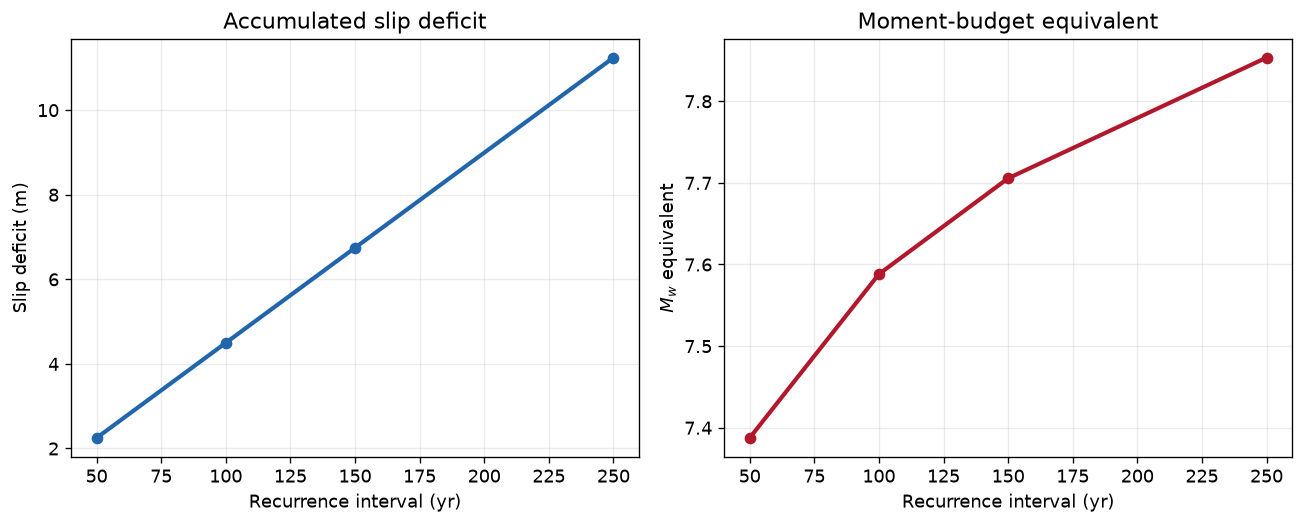

In [ ]:
coupling = 1.0
recurrence_years = np.array([50, 100, 150, 250])
rupture_length_km = 150.0   # km — length of the Mojave locked segment
rupture_width_km  =  15.0   # km — seismogenic width; try 10 and 20 to test sensitivity
shear_modulus_pa  =  30e9   # Pa — typical crustal shear modulus

slip_deficit_m = coupling * (V_fit * 1e-3) * recurrence_years
area_m2 = rupture_length_km*1e3 * rupture_width_km*1e3
moment_nm = shear_modulus_pa * area_m2 * slip_deficit_m
mw = (2/3) * (np.log10(moment_nm) - 9.1)

budget = pd.DataFrame({
    "recurrence_yr": recurrence_years,
    "slip_deficit_m": slip_deficit_m,
    "moment_Nm": moment_nm,
    "Mw_equivalent": mw,
})
display(budget)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].plot(recurrence_years, slip_deficit_m, "o-", color="#2166ac", lw=2.5)
axes[0].set(xlabel="Recurrence interval (yr)", ylabel="Slip deficit (m)",
            title="Accumulated slip deficit")
axes[1].plot(recurrence_years, mw, "o-", color="#b2182b", lw=2.5)
axes[1].set(xlabel="Recurrence interval (yr)", ylabel="$M_w$ equivalent",
            title="Moment-budget equivalent")
plt.tight_layout()
plt.show()


### Interpret the earthquake budget

1. How much slip deficit accumulates over 150 years?
2. Why does doubling recurrence interval not double moment magnitude?
3. Recalculate with $C=0.5$. What changes?
4. List at least three assumptions required to interpret this as one earthquake.
5. Change `rupture_width_km` to 10 km and then to 20 km. How much does $M_w$ change? Why is rupture width one of the harder parameters to constrain from surface geodesy alone?


---
# Part II: Coseismic Deformation

## 9. Ridgecrest M7.1 coseismic offsets

The 2019 Ridgecrest M7.1 earthquake produced coseismic GNSS offsets measured at hundreds of stations across southern California. These offsets were determined by the Nevada Geodetic Laboratory from 5-minute ultra-rapid solutions around the time of the earthquake.

In this section you will:
- load and parse the UNR offset file
- map the horizontal displacement vectors
- rotate offsets into fault coordinates
- plot and interpret a fault-perpendicular displacement profile

Archived data: [Nevada Geodetic Laboratory, UNR](https://geodesy.unr.edu/news_items/20190707/ci38457511_forweb.txt)  
Course copy: [datasets/Ridgecrest_coseismic/ci38457511_forweb.txt](https://github.com/amtseismo/EPS166/tree/main/datasets/Ridgecrest_coseismic)

**Event parameters (M7.1, 2019-07-06T03:19:53 UTC):**

| Parameter | Value |
|-----------|-------|
| Epicenter | 35.770°N, 117.599°W |
| Depth | 8 km |
| Strike | ~322° (NW-striking, right-lateral) |
| Mw | 7.1 |


In [ ]:
import io, urllib.request

# Event parameters
EQ_LAT    = 35.770
EQ_LON    = -117.599
EQ_STRIKE = 322.0   # degrees clockwise from north
EQ_DEPTH  = 8.0     # km

# GitHub raw URL for the UNR offset file
COSEISMIC_URL = (
    "https://raw.githubusercontent.com/amtseismo/EPS166/0ec7623208cddbdb1468d8519030b2125263a67e/datasets/Ridgecrest_GNSS_2019/unr_static_offsets.txt"
)

def load_unr_offsets(url):
    """
    Load UNR coseismic offset file.
    Format: Sta Lon Lat de(m) dn(m) du(m) sde sdn sdu
    Returns a DataFrame with columns in mm.
    """
    with urllib.request.urlopen(url) as r:
        text = r.read().decode()
    lines = [l for l in text.strip().split("\n")
             if l.strip() and not l.startswith("=") and not l.startswith("Sta")]
    records = []
    for line in lines:
        parts = line.split()
        if len(parts) >= 9:
            records.append({
                "station": parts[0],
                "lon":  float(parts[1]),
                "lat":  float(parts[2]),
                "de":   float(parts[3]) * 1000,  # m -> mm
                "dn":   float(parts[4]) * 1000,
                "du":   float(parts[5]) * 1000,
                "sde":  float(parts[6]) * 1000,
                "sdn":  float(parts[7]) * 1000,
                "sdu":  float(parts[8]) * 1000,
            })
    return pd.DataFrame(records)


offsets = load_unr_offsets(COSEISMIC_URL)
print(f"Loaded {len(offsets)} stations")
print(f"Max horizontal offset: {np.hypot(offsets.de, offsets.dn).max():.0f} mm")
display(offsets.head())


Loaded 481 stations
Max horizontal offset: 572 mm


,station,lon,lat,de,dn,du,sde,sdn,sdu
0,7ODM,-117.0932,34.1164,-5.34,5.27,-3.66,0.42,0.50,1.58
1,ACSB,-117.4449,33.2743,-5.19,3.58,3.37,0.37,0.45,1.42
2,ACSX,-117.4449,33.2743,-5.18,3.29,0.16,0.37,0.44,1.40
3,AGMT,-116.4294,34.5943,-4.36,3.29,2.49,0.38,0.46,1.45
4,ALTH,-120.6698,36.8896,-6.87,1.00,-0.07,0.39,0.47,1.48


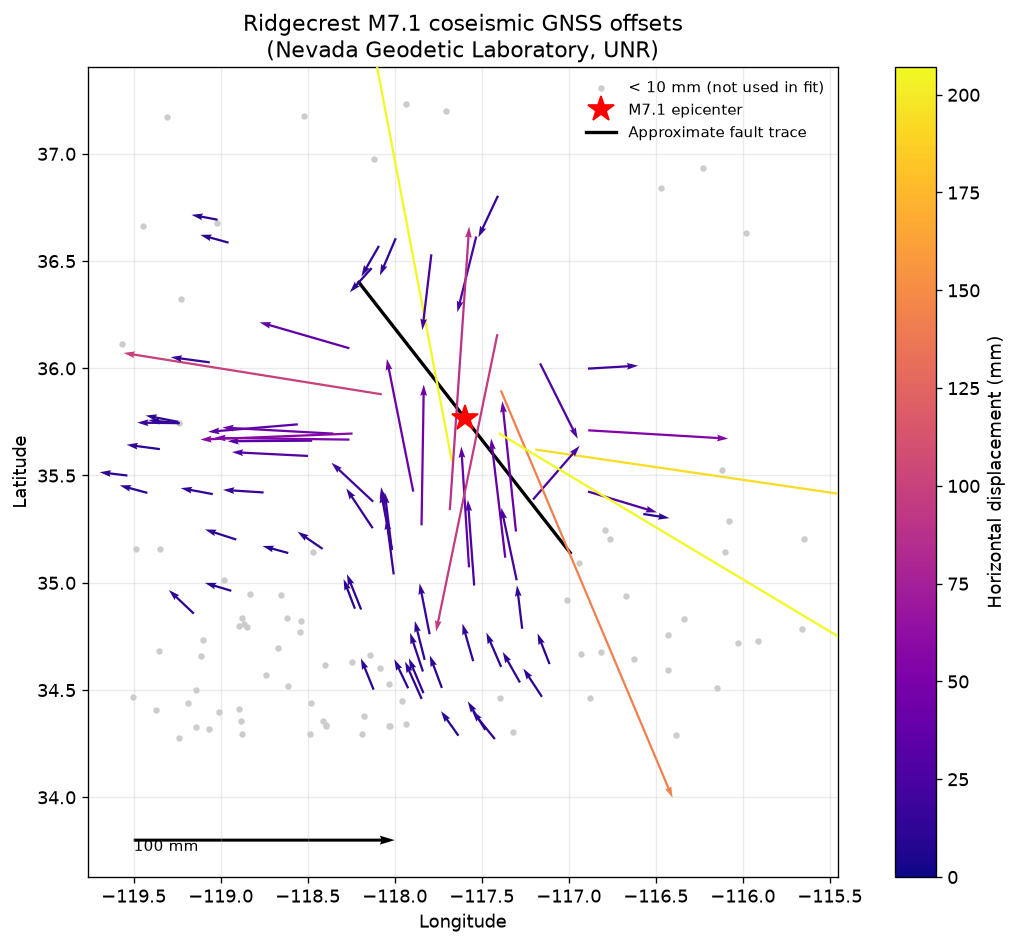

In [ ]:
# Filter to stations near the epicenter with significant offsets
horiz = np.sqrt(offsets.de**2 + offsets.dn**2)
near  = offsets[
    (np.abs(offsets.lon - EQ_LON) < 2.0) &
    (np.abs(offsets.lat - EQ_LAT) < 1.5)
].copy()
near["horiz_mm"] = np.hypot(near.de, near.dn)

# Split into significant and noise-dominated stations for the map
SIG_MM = 10.0   # matches MIN_HORIZ_OFFSET_MM in the fit cell
near_sig  = near[near.horiz_mm >= SIG_MM]
near_tiny = near[near.horiz_mm <  SIG_MM]

fig, ax = plt.subplots(figsize=(10, 8))

# Scale factor for quiver arrows
scale = 0.015  # degrees per mm

# Noise-dominated far-field stations as faint dots
ax.scatter(near_tiny.lon, near_tiny.lat, s=8, color="0.8", zorder=2,
           label=f"< {SIG_MM:.0f} mm (not used in fit)")

# Significant stations: displacement vectors coloured by offset magnitude
sc = ax.quiver(
    near_sig.lon, near_sig.lat,
    near_sig.de * scale, near_sig.dn * scale,
    near_sig.horiz_mm,
    scale=1, scale_units="xy", angles="xy",
    cmap="plasma", clim=(0, near_sig.horiz_mm.quantile(0.98)),
    zorder=3, width=0.003,
)
plt.colorbar(sc, ax=ax, label="Horizontal displacement (mm)")

# Epicenter
ax.plot(EQ_LON, EQ_LAT, "r*", ms=16, zorder=5, label="M7.1 epicenter")

# Approximate fault trace
strike_rad = np.deg2rad(EQ_STRIKE)
lengths = np.array([-0.8, 0.8])
fault_lon = EQ_LON + lengths * np.sin(strike_rad) / np.cos(np.deg2rad(EQ_LAT))
fault_lat = EQ_LAT + lengths * np.cos(strike_rad)
ax.plot(fault_lon, fault_lat, "k-", lw=2, label="Approximate fault trace")

# Scale arrow
ax.quiver(-119.5, 33.8, 100*scale, 0, scale=1, scale_units="xy",
          angles="xy", color="k", width=0.004)
ax.text(-119.5, 33.75, "100 mm", fontsize=9)

ax.set_aspect(1/np.cos(np.deg2rad(EQ_LAT)))
ax.set(xlabel="Longitude", ylabel="Latitude",
       title="Ridgecrest M7.1 coseismic GNSS offsets\n(Nevada Geodetic Laboratory, UNR)")
ax.legend(fontsize=9, frameon=False)
plt.tight_layout()
plt.show()


> **Interpret the offset map:**
> 1. Which station has the largest horizontal offset? Roughly how large is it?
> 2. Describe the overall pattern of displacement vectors — are stations on both sides of the fault moving in the same direction or opposite directions?
> 3. Is the pattern consistent with right-lateral slip on a NW-striking fault? Explain.
> 4. The offsets decay with distance from the fault. Does the decay look more like a sharp step or a broad gradient? How does this compare to the interseismic velocity profile?


## 10. Fit the 1D coseismic dislocation model

In lecture we saw that for a surface-rupturing strike-slip earthquake the fault-parallel displacement follows:

$$
u(x) = \frac{S}{\pi} \arctan\!\left(\frac{D}{x}\right)
$$

where $S$ is the average fault slip and $D$ is the seismogenic depth. Compare this to the interseismic model — the argument of the arctan is flipped: $D/x$ instead of $x/D$.

We rotate the coseismic offsets into fault coordinates and fit this model to the fault-perpendicular displacement profile.


Profile stations: 12  (dropped 3 with horiz offset < 10 mm)
Best-fit slip S  = 5000 ± 179 mm
Best-fit depth D = 2.6 ± 0.1 km
Published slip   ≈ 1500–3000 mm (from InSAR/seismic inversions)


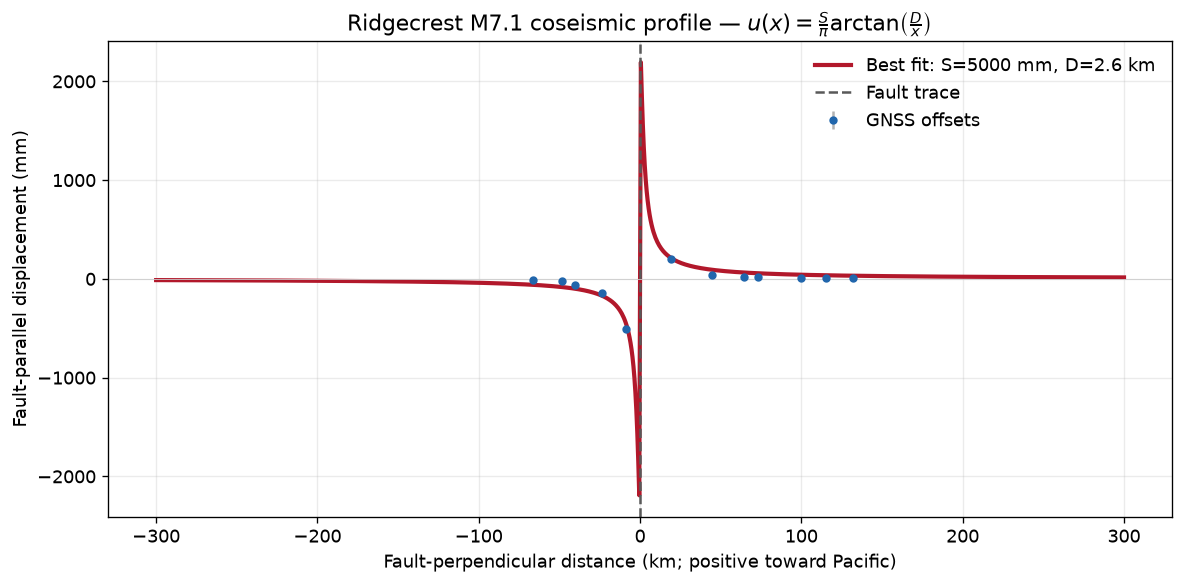

In [ ]:
# Rotate coseismic offsets into fault coordinates
# Reuse the rotate_to_fault_coordinates function from Part I
# Map column names to match: de->ve, dn->vn, sde->se, sdn->sn
offsets_renamed = offsets.rename(columns={"de": "ve", "dn": "vn",
                                           "sde": "se", "sdn": "sn"})
offsets_rot = rotate_to_fault_coordinates(
    offsets_renamed, EQ_LON, EQ_LAT, EQ_STRIKE
)

# Minimum horizontal offset to include a station.
# Far-field stations (>100 km) typically have offsets of 1–3 mm — at or below
# the noise floor of 5-minute UNR solutions (~3–5 mm). Including them pulls the
# arctan fit toward zero and biases both slip and depth estimates.
# Raising this threshold keeps only stations with a clear coseismic signal.
MIN_HORIZ_OFFSET_MM = 10.0

# Restrict along-strike to ±25 km — roughly half the NW fault length.
# The Ridgecrest rupture had two conjugate planes: a ~50 km NW-striking
# primary fault (strike 322°) and a ~16 km NE-striking secondary fault.
# Stations near the NE fault have offsets that don't fit a 1D NW-profile,
# so a wide along-strike window produces large scatter. Keeping only stations
# within ~25 km of the epicenter along-strike retains the NW fault signal
# and excludes most NE-fault contamination.
profile = offsets_rot[
    offsets_rot.x_parallel_km.abs().le(25) &
    offsets_rot.x_perp_km.abs().le(150)
].copy()
profile["horiz_mm"] = np.hypot(profile.ve, profile.vn)

# Offset magnitude filter — drop noise-dominated far-field stations
n_before = len(profile)
profile = profile[profile.horiz_mm >= MIN_HORIZ_OFFSET_MM].copy()
print(f"Profile stations: {len(profile)}  "
      f"(dropped {n_before - len(profile)} with horiz offset < {MIN_HORIZ_OFFSET_MM:.0f} mm)")


def coseismic_arctan(x_km, slip_mm, depth_km):
    """
    1D surface-rupture coseismic displacement model.
    u(x) = (S/pi) * arctan(D/x)
    Note: x=0 gives a discontinuity — we avoid it.
    """
    x = np.where(np.abs(x_km) < 0.1, 0.1 * np.sign(x_km + 1e-9), x_km)
    return (slip_mm / np.pi) * np.arctan(depth_km / x)


# Fit — use fault-parallel displacement (v_parallel)
# Sign convention: positive x = Pacific side (left of fault looking along strike)
from scipy.optimize import curve_fit

p0     = [1000.0, 10.0]          # initial: 1 m slip, 10 km depth
bounds = ([0.0, 1.0], [5000.0, 40.0])

try:
    params, pcov = curve_fit(
        coseismic_arctan,
        profile.x_perp_km,
        profile.v_parallel,
        p0=p0, bounds=bounds,
        sigma=profile.s_parallel,
        absolute_sigma=True,
    )
    perr = np.sqrt(np.diag(pcov))
    S_fit, D_fit_co = params
    print(f"Best-fit slip S  = {S_fit:.0f} ± {perr[0]:.0f} mm")
    print(f"Best-fit depth D = {D_fit_co:.1f} ± {perr[1]:.1f} km")
    print(f"Published slip   ≈ 1500–3000 mm (from InSAR/seismic inversions)")
except Exception as e:
    print(f"Fit failed: {e}")
    S_fit, D_fit_co = 2000.0, 10.0

# Plot
x_co = np.concatenate([np.linspace(-300, -0.5, 500), np.linspace(0.5, 300, 500)])
v_co = coseismic_arctan(x_co, S_fit, D_fit_co)

fig, ax = plt.subplots(figsize=(10, 5))
ax.errorbar(profile.x_perp_km, profile.v_parallel, yerr=profile.s_parallel,
            fmt="o", ms=4, color="#2166ac", ecolor="0.7", label="GNSS offsets", zorder=3)
ax.plot(x_co, v_co, color="#b2182b", lw=2.5,
        label=f"Best fit: S={S_fit:.0f} mm, D={D_fit_co:.1f} km")
ax.axvline(0, color="0.35", ls="--", lw=1.5, label="Fault trace")
ax.axhline(0, color="0.8", lw=0.5)
ax.set(xlabel="Fault-perpendicular distance (km; positive toward Pacific)",
       ylabel="Fault-parallel displacement (mm)",
       title=r"Ridgecrest M7.1 coseismic profile — $u(x) = \frac{S}{\pi}\arctan\!\left(\frac{D}{x}\right)$")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()


> **Interpret the coseismic model:**
> 1. How does your best-fit slip $S$ compare to published estimates of ~1.5–3 m average slip from InSAR and seismic inversions? What might explain differences?
> 2. The interseismic model uses $\arctan(x/D)$ and the coseismic model uses $\arctan(D/x)$. Describe in words how the shapes differ and why — which is peaked near the fault and which is broad?
> 3. Look at the residuals. Are there stations that deviate strongly from the 1D model? What physical factors might cause these deviations?
> 4. The 1D model assumes a single uniform slip value. Real fault ruptures have spatially variable slip — how would you expect that to affect the surface displacement pattern?
> 5. Using your best-fit slip $S$ and the moment budget formula from Section 9 with Ridgecrest rupture dimensions ($L \approx 50$ km, $W \approx 15$ km), compute the equivalent $M_w$. Does it agree with the catalog value of 7.1? What does any discrepancy tell you about the 1D model?


---
# Part III: Postseismic Deformation

## 11. Ridgecrest postseismic time series

Following the M7.1 earthquake, GNSS stations near the fault recorded continued motion as the crust responded to the stress change. We use daily position time series from the Nevada Geodetic Laboratory (NGL) tenv3 archive, which provides positions in the IGS14 reference frame.

We load time series for **P595** — the nearest station to the M7.1 epicenter (~13 km), which had the largest coseismic offset (~520 mm east) and should show the clearest postseismic signal.

The tenv3 format provides daily positions. We will:
1. Download and parse the time series
2. Identify the coseismic step and subtract interseismic trend
3. Isolate the postseismic residual
4. Fit a logarithmic afterslip model

Archived data: [NGL tenv3 archive](http://geodesy.unr.edu/gps_timeseries/tenv3/IGS14/)  
Format documentation: [UNR tenv3 format](http://geodesy.unr.edu/gps_timeseries/tenv3/IGS14/0README_tenv3.txt)


In [ ]:
from datetime import datetime, timedelta

# M7.1 origin time
EQ_DATE = datetime(2019, 7, 6)

# Stations to load — P595 is nearest to M7.1, P580 is intermediate distance
# Static copies of the NGL tenv3 time series hosted in the course GitHub repo.
# The NGL live server (geodesy.unr.edu) is unreliable from Colab — it
# rate-limits automated downloads and is sometimes unavailable.
# To regenerate these files: download P595.tenv3 and P580.tenv3 from
#   http://geodesy.unr.edu/gps_timeseries/tenv3/IGS14/
# and commit them to datasets/Ridgecrest_GNSS_2019/ in the course repo.
POSTSEISMIC_URLS = {
    "P595": "https://raw.githubusercontent.com/amtseismo/EPS166/6b64289adcee4e386a7ef0165f9b8bcf58da1831/datasets/Ridgecrest_GNSS_2019/P595.tenv3",
    "P580": "https://raw.githubusercontent.com/amtseismo/EPS166/6b64289adcee4e386a7ef0165f9b8bcf58da1831/datasets/Ridgecrest_GNSS_2019/P580.tenv3",
}
NGL_BASE = "http://geodesy.unr.edu/gps_timeseries/tenv3/IGS14/"  # fallback


def load_ngl_tenv3(station, base_url=NGL_BASE, full_url=None):
    """
    Load a NGL tenv3 daily position time series.

    tenv3 columns (relevant ones):
        col 0: station
        col 2: decimal year
        col 8: east  displacement from reference (m)
        col 10: north displacement from reference (m)
        col 12: up    displacement from reference (m)
        col 14: east  uncertainty (m)
        col 15: north uncertainty (m)
        col 16: up    uncertainty (m)

    Returns DataFrame with columns: year_dec, east_mm, north_mm, up_mm,
    se_mm, sn_mm, su_mm, date.
    """
    url = full_url if full_url is not None else f"{base_url}{station}.tenv3"
    try:
        with urllib.request.urlopen(url, timeout=30) as r:
            text = r.read().decode()
    except Exception as e:
        print(f"  {station}: could not download ({e})")
        return None

    rows = []
    for line in text.strip().split("\n"):
        if line.startswith("*") or len(line) < 10:
            continue
        parts = line.split()
        if len(parts) < 17:
            continue
        try:
            rows.append({
                "year_dec":  float(parts[2]),
                "east_mm":   float(parts[8])  * 1000,
                "north_mm":  float(parts[10]) * 1000,
                "up_mm":     float(parts[12]) * 1000,
                "se_mm":     float(parts[14]) * 1000,
                "sn_mm":     float(parts[15]) * 1000,
                "su_mm":     float(parts[16]) * 1000,
            })
        except (ValueError, IndexError):
            continue

    df = pd.DataFrame(rows)
    # Convert decimal year to datetime
    def decyr_to_date(y):
        yr = int(y)
        frac = y - yr
        return datetime(yr, 1, 1) + timedelta(days=frac * 365.25)
    df["date"] = df.year_dec.apply(decyr_to_date)
    df["days_from_eq"] = (df.date - EQ_DATE).dt.days
    return df


print("Downloading GNSS time series...")
ts_data = {}
for sta, url in POSTSEISMIC_URLS.items():
    print(f"  {sta} (GitHub)...", end=" ")
    df = load_ngl_tenv3(sta, base_url=None, full_url=url)
    if df is None:
        print(f"GitHub failed, trying NGL fallback...")
        df = load_ngl_tenv3(sta, base_url=NGL_BASE)
    if df is not None:
        ts_data[sta] = df
        print(f"OK ({len(df)} days, {df.year_dec.min():.1f}–{df.year_dec.max():.1f})")


  P595 (GitHub)... OK (6874 days, 2005.8–2024.6)
  P580 (GitHub)... OK (6381 days, 2007.1–2024.6)


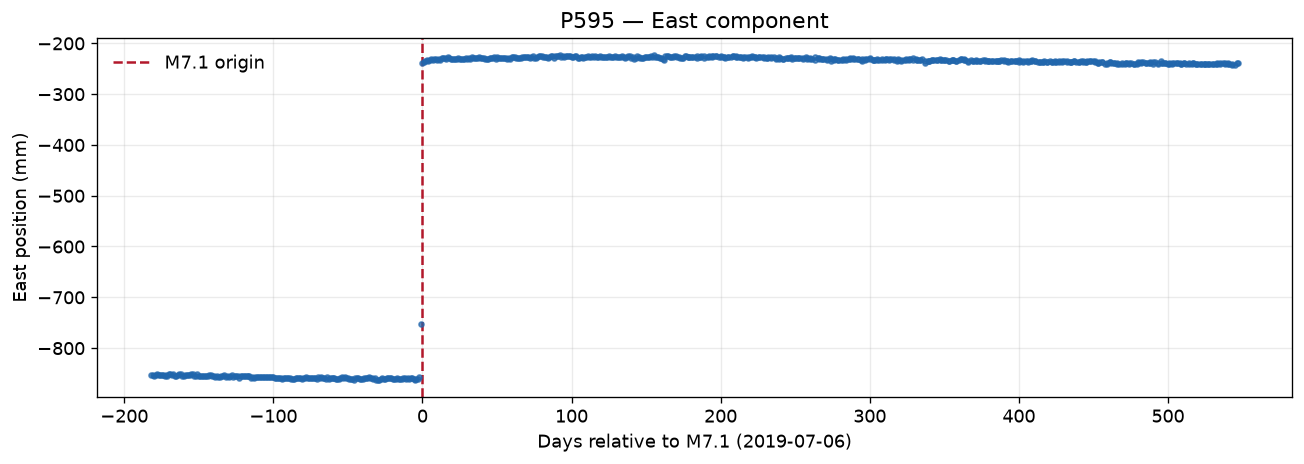

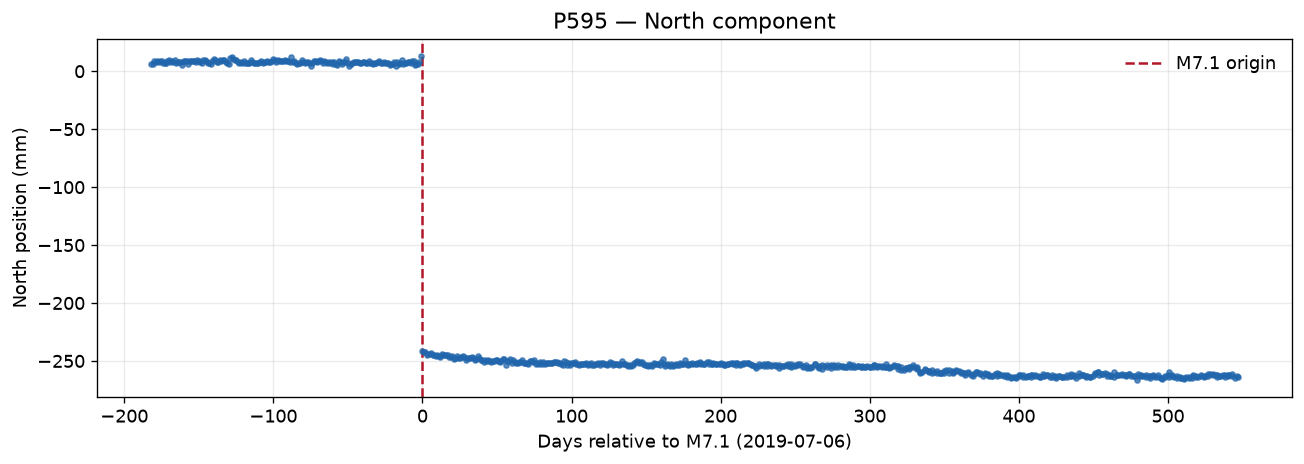

In [ ]:
def plot_timeseries(df, station, component="east", window_years=(-1, 2)):
    """
    Plot a GNSS position time series centred on the earthquake.

    Parameters
    ----------
    df : pd.DataFrame
        Output from load_ngl_tenv3.
    station : str
        Station name for the title.
    component : str
        'east', 'north', or 'up'.
    window_years : tuple
        Time window relative to earthquake in years.
    """
    col = f"{component}_mm"
    scol = f"s{component[0]}_mm"

    mask = (
        (df.days_from_eq >= window_years[0] * 365) &
        (df.days_from_eq <= window_years[1] * 365)
    )
    sub = df[mask].copy()

    fig, ax = plt.subplots(figsize=(11, 4))
    ax.errorbar(sub.days_from_eq, sub[col], yerr=sub[scol],
                fmt="o", ms=3, color="#2166ac", ecolor="0.7", alpha=0.7)
    ax.axvline(0, color="#b2182b", lw=1.5, ls="--", label="M7.1 origin")
    ax.set(xlabel="Days relative to M7.1 (2019-07-06)",
           ylabel=f"{component.capitalize()} position (mm)",
           title=f"{station} — {component.capitalize()} component")
    ax.legend(frameon=False)
    plt.tight_layout()
    plt.show()


# Plot east component for P595 — shows coseismic step and postseismic
if "P595" in ts_data:
    plot_timeseries(ts_data["P595"], "P595", component="east", window_years=(-0.5, 1.5))
    plot_timeseries(ts_data["P595"], "P595", component="north", window_years=(-0.5, 1.5))


> **Inspect the time series:**
> 1. Identify the coseismic step in the east component. Roughly how large is it? Does it agree with the offset file from Part II?
> 2. After the coseismic step, does the station continue to move or does it return to its pre-earthquake velocity immediately? Describe what you see in the first few weeks after the earthquake.
> 3. Compare the east and north components. Which shows the larger coseismic offset? Is this consistent with right-lateral slip on a NW-striking fault?
> 4. Approximately how long does the postseismic signal appear to persist before returning to a steady rate?


## 12. Fit a logarithmic afterslip model

In lecture we saw that afterslip produces a characteristic logarithmic time decay:

$$
u_{\text{post}}(t) = A \log\!\left(1 + \frac{t}{\tau}\right)
$$

where $A$ is the afterslip amplitude (mm), $\tau$ is the characteristic decay time (days), and $t$ is days after the earthquake.

To isolate the postseismic signal we must remove two things from the raw time series:

1. **The interseismic trend** — estimated by fitting a line to the pre-earthquake portion of the record.
2. **The coseismic step** — estimated as the difference between the extrapolated pre-earthquake trend and the first post-earthquake observation.

Both choices involve a window. The defaults below were chosen to be well clear of the coseismic transient for the pre-earthquake window and to avoid the very first days (when data can be noisy) for the post-earthquake window. **You can and should experiment with these to see how sensitive your afterslip amplitude and decay time are to the window choice** — that sensitivity is part of understanding the uncertainty in postseismic analyses.

```python
# Windows used in isolate_postseismic (days relative to the earthquake)
PRE_WINDOW  = (-365, -10)   # days before earthquake used to estimate interseismic rate
POST_WINDOW = (3, 500)      # days after earthquake used to fit afterslip
```

These are passed to the `isolate_postseismic` function below. Try changing `PRE_WINDOW` to `(-180, -10)` and `POST_WINDOW` to `(3, 200)` and observe whether $A$ and $\tau$ change substantially.


Estimated interseismic rate: -19.9 mm/yr
Estimated coseismic offset:  630 mm
Postseismic window: 3 to 500 days

Best-fit afterslip amplitude A = 6.5 ± 0.2 mm
Best-fit decay time tau        = 20.2 ± 1.4 days


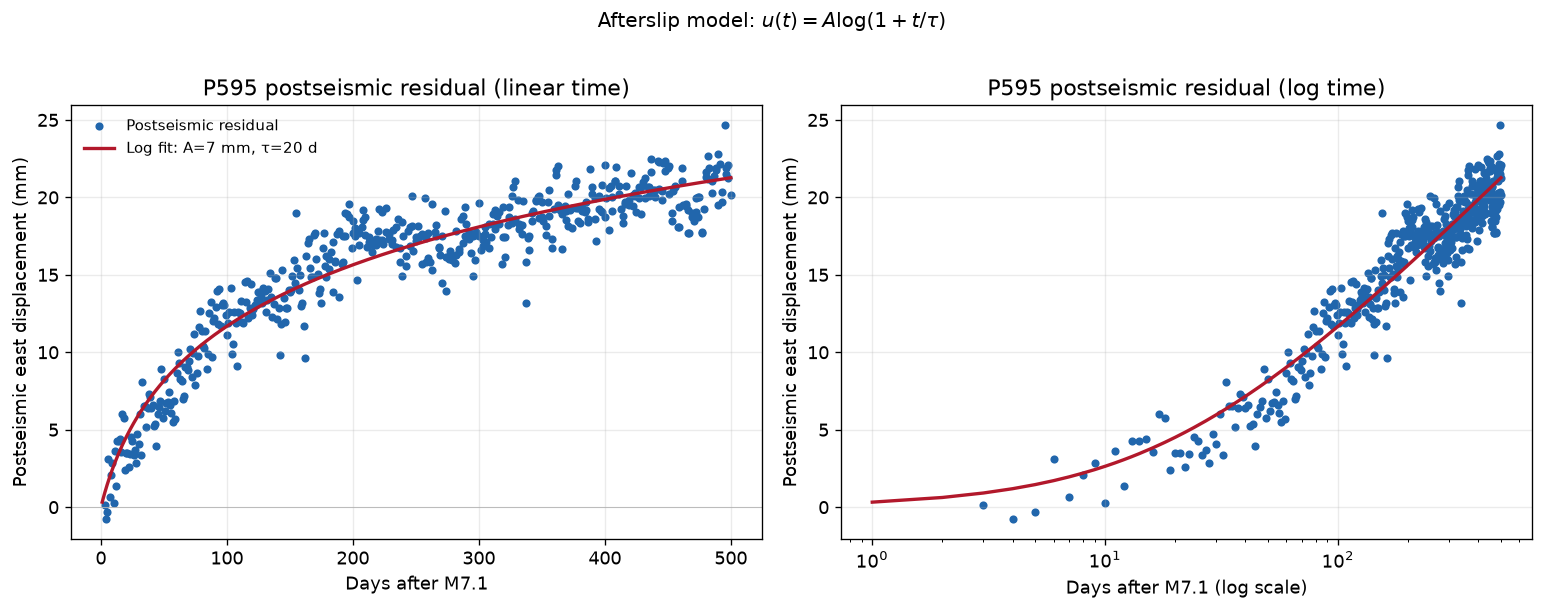

In [ ]:
# ── Adjust these windows and rerun to test sensitivity ──────────────────────────
PRE_WINDOW  = (-365, -10)  # days before earthquake for interseismic rate estimate
POST_WINDOW = (  3,  500)  # days after earthquake for afterslip fitting
# ─────────────────────────────────────────────────────────────────────────────────

def isolate_postseismic(df, component="east",
                         pre_window_days=PRE_WINDOW,
                         post_window_days=POST_WINDOW):
    """
    Isolate the postseismic displacement by removing the interseismic
    trend and coseismic step.

    Returns
    -------
    t_post : np.array
        Days after earthquake.
    u_post : np.array
        Postseismic displacement in mm.
    pre_rate : float
        Estimated interseismic rate in mm/day.
    co_offset : float
        Estimated coseismic offset in mm.
    """
    col  = f"{component}_mm"
    scol = f"s{component[0]}_mm"

    # Pre-earthquake data
    pre = df[(df.days_from_eq >= pre_window_days[0]) &
             (df.days_from_eq <= pre_window_days[1])].copy()
    # Fit linear trend to pre-earthquake
    pre_fit = np.polyfit(pre.days_from_eq, pre[col], 1)
    pre_rate = pre_fit[0]   # mm/day

    # Post-earthquake data
    post = df[(df.days_from_eq >= post_window_days[0]) &
              (df.days_from_eq <= post_window_days[1])].copy()

    # Predicted position from interseismic trend at t=0
    trend_at_eq = np.polyval(pre_fit, 0)
    # Observed position just after the earthquake (first available day)
    obs_after = post.iloc[0][col]
    co_offset  = obs_after - trend_at_eq

    # Remove trend and coseismic offset from post-seismic data
    t_post = post.days_from_eq.values
    u_post = post[col].values - np.polyval(pre_fit, t_post) - co_offset

    return t_post, u_post, pre_rate, co_offset


def log_afterslip(t, A, tau):
    """Logarithmic afterslip model."""
    return A * np.log1p(t / tau)


if "P595" in ts_data:
    t_post, u_post, pre_rate, co_offset = isolate_postseismic(
        ts_data["P595"], component="east"
    )

    print(f"Estimated interseismic rate: {pre_rate * 365:.1f} mm/yr")
    print(f"Estimated coseismic offset:  {co_offset:.0f} mm")
    print(f"Postseismic window: {t_post[0]:.0f} to {t_post[-1]:.0f} days")

    # Fit logarithmic model
    try:
        popt, pcov = curve_fit(
            log_afterslip, t_post, u_post,
            p0=[50.0, 10.0],
            bounds=([0, 0.1], [500, 500]),
        )
        perr = np.sqrt(np.diag(pcov))
        A_fit, tau_fit = popt
        print(f"\nBest-fit afterslip amplitude A = {A_fit:.1f} ± {perr[0]:.1f} mm")
        print(f"Best-fit decay time tau        = {tau_fit:.1f} ± {perr[1]:.1f} days")
    except Exception as e:
        print(f"Fit failed: {e}")
        A_fit, tau_fit = 50.0, 10.0

    # Plot
    t_model = np.linspace(1, t_post[-1], 500)
    u_model = log_afterslip(t_model, A_fit, tau_fit)

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    # Linear time axis
    axes[0].scatter(t_post, u_post, s=15, color="#2166ac", label="Postseismic residual")
    axes[0].plot(t_model, u_model, color="#b2182b", lw=2,
                 label=f"Log fit: A={A_fit:.0f} mm, τ={tau_fit:.0f} d")
    axes[0].axhline(0, color="0.7", lw=0.5)
    axes[0].set(xlabel="Days after M7.1", ylabel="Postseismic east displacement (mm)",
                title="P595 postseismic residual (linear time)")
    axes[0].legend(frameon=False, fontsize=9)

    # Log time axis
    axes[1].scatter(t_post, u_post, s=15, color="#2166ac")
    axes[1].plot(t_model, u_model, color="#b2182b", lw=2)
    axes[1].set_xscale("log")
    axes[1].set(xlabel="Days after M7.1 (log scale)",
                ylabel="Postseismic east displacement (mm)",
                title="P595 postseismic residual (log time)")

    plt.suptitle(
        r"Afterslip model: $u(t) = A\log\!(1 + t/\tau)$",
        fontsize=12, y=1.01
    )
    plt.tight_layout()
    plt.show()


> **Interpret the afterslip model:**
> 1. How large is the total afterslip amplitude $A$? How does it compare to the coseismic offset at P595?
> 2. What is the characteristic decay time $\tau$? In physical terms, what does $\tau$ represent?
> 3. On the log time axis, a perfect logarithmic decay would appear as a straight line. Does your residual follow this pattern? Are there deviations — and if so, at what timescales?
> 4. In lecture we discussed three postseismic mechanisms: afterslip, poroelastic rebound, and viscoelastic relaxation. Based on the timescale and amplitude of the signal you fitted, which mechanism does this most likely represent? What observations would you need to distinguish them definitively?
> 5. The postseismic signal at P595 continues for months after the earthquake. If you measured the interseismic velocity of P595 one year after the earthquake, would it equal the true long-term interseismic rate? What bias would this introduce into a locking model?


---
## 13. Synthesis

Write a short paragraph (4–6 sentences) for each question below.

> **1. The complete earthquake cycle at Ridgecrest**  
> You have now seen three phases of the earthquake cycle at a single fault system: interseismic loading on the San Andreas (a proxy for the locked phase), coseismic offsets from the M7.1, and postseismic relaxation at P595. Describe how the deformation pattern — spatial extent, amplitude, and temporal behavior — changes across these three phases. What does each phase tell you that the others cannot?

> **2. The arctan flip**  
> The interseismic velocity profile follows $v(x) = \frac{V_s}{\pi}\arctan(x/D)$ and the coseismic displacement profile follows $u(x) = \frac{S}{\pi}\arctan(D/x)$. Describe in physical terms why the argument of the arctan is flipped between the two cases. What does each parameter ($V_s$ vs $S$, $D$ in each context) represent physically?

> **3. Postseismic contamination of interseismic velocities**  
> Suppose you built a GNSS velocity field for southern California using data collected from 2019–2021 — immediately after the Ridgecrest sequence. How would the postseismic signal affect your estimate of interseismic locking on nearby faults? Would you overestimate or underestimate the locking depth, and why?

### References

- Kreemer, C., Hammond, W. C., and Blewitt, G. (2022). Crustal Strain Rates in the Western United States and Their Relationship with Earthquake Rates. https://doi.org/10.7910/DVN/BICMWB
- Savage, J. C. and Burford, R. O. (1973). Geodetic determination of relative plate motion in central California. *Journal of Geophysical Research*, 78(5), 832–845. https://doi.org/10.1029/JB078i005p00832
- Nevada Geodetic Laboratory, University of Nevada Reno. http://geodesy.unr.edu
- Reid, H. F. (1910). *The Mechanics of the Earthquake*. Carnegie Institution of Washington.
